# 01 · BRS soil geochemistry (Baleshwar–Dariba, Khetri Copper Belt)

Thin driver over `geompm.data.brs`. Changes vs. the original notebook (see module docstring):

| Issue in original | Fix |
|---|---|
| `"<10"` parsed as 9 → target "Cu ≥ 10" meant *detected*, not *anomalous* | censored values → DL/2 + flag column; threshold is an explicit, data-driven choice |
| PC1 built from Zn, Ni, Co **and Cu** while predicting Cu | geochemical feature excludes the target element |
| proximity centre picked using validation rows; distance in degrees; k = +0.95 hand-set | fitted per training fold, haversine km, k estimated by Poisson ML |
| random 80/20 split on spatially autocorrelated samples | spatial-block GroupKFold |

In [1]:
import os, sys
from pathlib import Path
# run from the repo root so relative data paths resolve
if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

C:\Users\Asus\OneDrive\Desktop\Rare_Earth_Elements


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from geompm.data.brs import load_brs, robust_anomaly_threshold, spatial_blocks, BRSFeatures, make_labels

df = load_brs("data/raw/BRS_Report.XLS")
print(df.shape)
print("Censoring per element:\n", pd.DataFrame({e: df[f"{e}_censored"].value_counts() for e in ["Cu","Pb","Zn","Ni","Co","Ag","Cd"]}).fillna(0).astype(int))
d = df.dropna(subset=["Cu", "latitude", "longitude"]).copy()
print("usable rows:", len(d))

(393, 18)
Censoring per element:
     Cu   Pb   Zn   Ni   Co   Ag   Cd
   319   53  387  346  250   30  178
<   74  340    6   47  143  363  215
usable rows: 323


## Anomaly threshold — a research decision
Cu is strongly right-skewed (median ≈ 35 ppm, max 4500 ppm). The table shows how many samples each common threshold labels anomalous. **`THRESHOLD` below is a choice to justify in the write-up** (default here: median + 1·MAD of log10 Cu).

In [3]:
rows = [(f"median + {n} MAD (log10)", robust_anomaly_threshold(d.Cu, n)) for n in (1, 1.5, 2)]
rows += [(f"{q}th percentile", np.percentile(d.Cu, q)) for q in (75, 80, 90)]
rows += [("old notebook (detection limit)", 10.0)]
print(pd.DataFrame([(n, round(t), int((d.Cu >= t).sum())) for n, t in rows], columns=["rule", "ppm", "n_anomalous"]).to_string(index=False))
THRESHOLD = robust_anomaly_threshold(d.Cu, 1)
d["y"] = make_labels(d, "Cu", THRESHOLD)
print("\nTHRESHOLD =", round(THRESHOLD), "ppm ->", d.y.value_counts().to_dict())

                          rule  ppm  n_anomalous
        median + 1 MAD (log10)  243           57
      median + 1.5 MAD (log10)  759           24
        median + 2 MAD (log10) 2368            5
               75th percentile  140           81
               80th percentile  192           65
               90th percentile  551           33
old notebook (detection limit)   10          250

THRESHOLD = 243 ppm -> {0: 266, 1: 57}


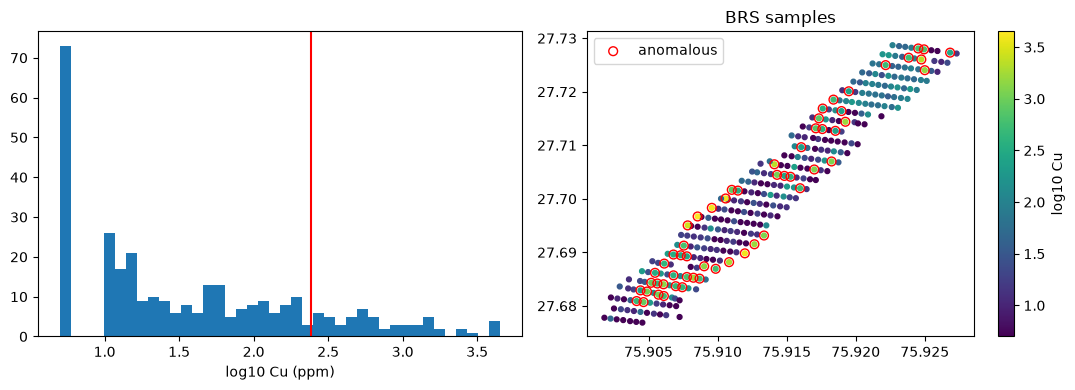

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.log10(d.Cu), bins=40); ax[0].axvline(np.log10(THRESHOLD), c="r"); ax[0].set_xlabel("log10 Cu (ppm)")
sc = ax[1].scatter(d.longitude, d.latitude, c=np.log10(d.Cu), s=12, cmap="viridis"); plt.colorbar(sc, ax=ax[1], label="log10 Cu")
ax[1].scatter(d.longitude[d.y == 1], d.latitude[d.y == 1], facecolors="none", edgecolors="r", s=40, label="anomalous")
ax[1].legend(); ax[1].set_title("BRS samples"); plt.tight_layout(); plt.show()

## Spatial cross-validation with fold-safe features

In [5]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

groups = spatial_blocks(d.latitude, d.longitude, block_km=0.5)
print("spatial blocks:", len(np.unique(groups)))
models = {
    "RandomForest": lambda: RandomForestClassifier(300, max_depth=5, class_weight="balanced", random_state=42),
    "HistGB": lambda: HistGradientBoostingClassifier(max_depth=3, class_weight="balanced", random_state=42),
}
records, ks = [], []
for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(d, d.y, groups)):
    feats = BRSFeatures("Cu", THRESHOLD, ["Zn", "Ni", "Co"]).fit(d.iloc[tr])
    ks.append(feats.fit_.k)
    Xtr, Xte = feats.transform(d.iloc[tr])[["w_proximity", "g_pc1"]], feats.transform(d.iloc[te])[["w_proximity", "g_pc1"]]
    for name, make in models.items():
        p = make().fit(Xtr, d.y.iloc[tr]).predict_proba(Xte)[:, 1]
        if d.y.iloc[te].nunique() == 2:
            records.append({"fold": fold, "model": name, "roc_auc": roc_auc_score(d.y.iloc[te], p), "pr_auc": average_precision_score(d.y.iloc[te], p), "prevalence": d.y.iloc[te].mean()})
res = pd.DataFrame(records)
print("fitted k per fold:", np.round(ks, 3))
print(res.groupby("model")[["roc_auc", "pr_auc", "prevalence"]].agg(["mean", "std"]).round(3))

spatial blocks: 28


C:\Users\Asus\OneDrive\Desktop\Rare_Earth_Elements\src\geompm\geology\spatial_prior.py:135: UserWarning: Fitted k = 0.075 >= 0: mineralisation does not decay with distance to this factor; it may not be ore-controlling at this scale.
  warnings.warn(


C:\Users\Asus\OneDrive\Desktop\Rare_Earth_Elements\src\geompm\geology\spatial_prior.py:135: UserWarning: Fitted k = 0.036 >= 0: mineralisation does not decay with distance to this factor; it may not be ore-controlling at this scale.
  warnings.warn(


fitted k per fold: [-0.182  0.075 -0.031 -0.089  0.036]
             roc_auc        pr_auc        prevalence       
                mean    std   mean    std       mean    std
model                                                      
HistGB         0.527  0.098  0.224  0.105      0.177  0.106
RandomForest   0.557  0.108  0.250  0.101      0.177  0.106


**Reading the result.** Compare PR-AUC with the prevalence (the PR-AUC of a random classifier). k close to 0 means Cu anomalies do not decay with distance from the single richest sample at this survey scale. The single-centre proximity feature is a weak prior here. Mapped structures (faults, contacts) from GSI 1:50k geology would be the proper controlling factors.